# HealthRAG — Etapas 5 y 7: agentes y evaluación

Para usar un LLM real configurar `.env` (ver `.env.example`). Sin API key el sistema funciona en modo **extractivo** (línea de base sin LLM).

In [1]:
import os, sys
from pathlib import Path

# Raíz del proyecto: funciona abriendo el notebook desde notebooks/ o desde la raíz.
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))

from app.config import load_config, resolve_path
from app.utils.logging_config import configure_logging

cfg = load_config()
logger = configure_logging(cfg)
print("Proyecto:", ROOT)

Proyecto: HealthRAG


In [2]:
from app.rag.pipeline import HealthRAGService
service = HealthRAGService(cfg)
print('Proveedor:', service.provider)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

HealthRAG\app\retrieval\embedder.py:34: FutureWarning: The `get_sentence_embedding_dimension` method has been renamed to `get_embedding_dimension`.
  self.dim = int(self._model.get_sentence_embedding_dimension())
2026-11-15 12:50:53,541 | INFO | healthrag.retrieval.embedder | Embeddings: intfloat/multilingual-e5-small (dim=384)


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

2026-11-15 12:51:00,423 | INFO | healthrag.retrieval.reranker | Reranker cargado: cross-encoder/mmarco-mMiniLMv2-L12-H384-v1


2026-11-15 12:51:01,742 | INFO | healthrag.retrieval | Retriever listo: 1514 chunks (1316 ms)


2026-11-15 12:51:01,742 | INFO | healthrag.llm | Proveedor LLM: extractivo (sin modelo generativo)


Proveedor: extractive


In [3]:
r = service.answer('cuanta sal se recomienda consumir por dia', mode='multiagent', use_cache=False)
print(r['answer'], '\n')
for s in r['sources']: print(f"[{s['eid']}] {s['citation']}")
print('\nDiálogo entre agentes:')
for m in r['trace']: print(f"  {m['from']} -> {m['to']} [{m['type']}]", str(m['content'])[:160])
print('\nLatencia (ms):', round(r['latency_ms']), '| tokens:', r['tokens'], '| costo US$', r['cost_usd'])

2026-11-15 12:51:05,957 | INFO | healthrag.pipeline | Consulta 952b8fae8af2 [multiagent] 4168 ms, abstención=False, tokens=0


Se estima que el consumo diario de sal en nuestro país supera los 10 g (alrededor de 4000 mg de sodio), duplicando la recomendación actual. [E3] El 70% del consumo diario de sodio corresponde a la sal oculta, que es aportada por los alimentos industrializados en forma de conservantes y aditivos. [E3] Para reducir el consumo de sal se aconseja: 1.Preferir alimentos naturales frescos o mínimamente procesados. [E3] 

[E3] Guía de Práctica Clínica Nacional de Prevención, Diagnóstico y Tratamiento de la Hipertensión Arterial (HTA). Versión breve para el equipo de salud, Ministerio de Salud de la Nación (Argentina), 2026, sección «Reducción de sodio», pág. 14

Diálogo entre agentes:
  recuperador -> analista [evidencia] {'query': 'cuanta sal se recomienda consumir por dia', 'retrieved': ['Guia_OMS_prev_ECV_p32_c87', 'Guia_OMS_prev_ECV_p24_c65', 'GPCN_HTA_p14_c41', 'GPCN_prev_ca
  analista -> verificador [borrador] {'iteration': 1, 'abstain': False, 'n_claims': 3, 'issues': []}
  verificador 

## Experimentos EXP1–EXP4
Resultados en `reports/`. El conjunto de consultas está en `data/evaluation/queries.csv` — completar las páginas relevantes (`DOC_ID:PAG`) para métricas a nivel página.

In [4]:
from app.evaluation.run_experiments import run
paths = run(exp4=True, service=service)
from IPython.display import Markdown, Image
display(Markdown(paths['markdown'].read_text(encoding='utf-8')))

2026-11-15 12:51:06,091 | INFO | healthrag.evaluation | Evaluación: 29 consultas, proveedor=extractive


2026-11-15 12:52:36,122 | INFO | healthrag.evaluation | EXP1 (basic)


2026-11-15 12:52:36,138 | INFO | healthrag.pipeline | Consulta c8740b4c6193 [basic] 10 ms, abstención=False, tokens=0


2026-11-15 12:52:36,310 | INFO | healthrag.pipeline | Consulta 8a1bbea65234 [basic] 12 ms, abstención=False, tokens=0


2026-11-15 12:52:36,762 | INFO | healthrag.pipeline | Consulta 88628e4f6fbc [basic] 11 ms, abstención=True, tokens=0


2026-11-15 12:52:36,779 | INFO | healthrag.pipeline | Consulta 2cfe50ab1151 [basic] 11 ms, abstención=False, tokens=0


... (170 outputs left out)

2026-11-15 13:05:12,375 | INFO | healthrag.pipeline | Consulta a3eef00de13e [multiagent] 7670 ms, abstención=True, tokens=0


2026-11-15 13:05:20,008 | INFO | healthrag.pipeline | Consulta aaf79be67341 [multiagent] 7618 ms, abstención=True, tokens=0


2026-11-15 13:05:23,285 | INFO | healthrag.evaluation | Resultados en HealthRAG\reports


# Resultados de evaluación — HealthRAG

- Consultas: 29 (con evidencia de referencia: 24; a nivel página: 24)
- Proveedor LLM: extractive · Embeddings: intfloat/multilingual-e5-small · Reranker: cross-encoder/mmarco-mMiniLMv2-L12-H384-v1
- Duración total: 854.4 s

## Recuperación

| retrieval_mode   |   retrieval_ms |   useful_context@5 |    mrr |   hit@5 |   recall@5 |   precision@5 |   ndcg@5 |   hit@10 |   recall@10 |   precision@10 |   ndcg@10 |
|:-----------------|---------------:|-------------------:|-------:|--------:|-----------:|--------------:|---------:|---------:|------------:|---------------:|----------:|
| advanced         |      3693.85   |             0.3333 | 0.7267 |  0.9583 |     0.875  |        0.3333 |   0.6246 |   1      |      0.9583 |         0.225  |    0.7199 |
| basic            |        49.3485 |             0.3083 | 0.691  |  0.875  |     0.7708 |        0.3083 |   0.5901 |   0.9583 |      0.9375 |         0.2333 |    0.7131 |
| hybrid           |         4.5985 |             0.35   | 0.7431 |  0.9167 |     0.8542 |        0.35   |   0.659  |   0.9583 |      0.9375 |         0.2375 |    0.7554 |

(tabla completa con k=1,3,5,10 en `retrieval_summary.csv`)

## Respuestas (EXP1–EXP4)

| exp                 | mode       |   n |   abstained |   correct_abstention |   false_abstention |   faithfulness |   citation_precision |   cited_source_relevance |   context_hit |   redundancy |   iterations |   tokens |   cost_usd |   rougeL |   bleu |   semantic_sim |   latency_p50_ms |   latency_p95_ms |
|:--------------------|:-----------|----:|------------:|---------------------:|-------------------:|---------------:|---------------------:|-------------------------:|--------------:|-------------:|-------------:|---------:|-----------:|---------:|-------:|---------------:|-----------------:|-----------------:|
| EXP1                | basic      |  29 |      0.2414 |                  1   |             0.0833 |              1 |                    1 |                   0.5909 |        0.875  |       0      |       1      |        0 |          0 |   0.3054 | 0.1362 |         0.9203 |          10.736  |          65.7645 |
| EXP2                | advanced   |  29 |      0.2069 |                  0.8 |             0.0833 |              1 |                    1 |                   0.6061 |        0.9583 |       0.0287 |       1      |        0 |          0 |   0.2876 | 0.1156 |         0.9223 |        3757.04   |        5494.69   |
| EXP3                | multiagent |  29 |      0.2069 |                  0.8 |             0.0833 |              1 |                    1 |                   0.6061 |        0.9583 |       0.0287 |       1.2069 |        0 |          0 |   0.2876 | 0.1156 |         0.9223 |        3798.89   |        9751.17   |
| EXP4_cache_caliente | multiagent |  29 |      0.2069 |                  0.8 |             0.0833 |              1 |                    1 |                   0.6061 |        0.9583 |       0.0287 |       1.2069 |        0 |          0 |   0.2876 | 0.1156 |         0.9223 |           0.2687 |           0.4445 |
| EXP4_cache_frio     | multiagent |  29 |      0.2069 |                  0.8 |             0.0833 |              1 |                    1 |                   0.6061 |        0.9583 |       0.0287 |       1.2069 |        0 |          0 |   0.2876 | 0.1156 |         0.9223 |        4383.92   |        9100.91   |
| EXP4_top3           | multiagent |  29 |      0.2069 |                  0.8 |             0.0833 |              1 |                    1 |                   0.6136 |        0.9167 |       0.0287 |       1.2759 |        0 |          0 |   0.2907 | 0.1189 |         0.9222 |        3956.42   |        8363.79   |
| EXP4_top8           | multiagent |  29 |      0.2069 |                  0.8 |             0.0833 |              1 |                    1 |                   0.5379 |        1      |       0.0287 |       1.2069 |        0 |          0 |   0.2621 | 0.1003 |         0.9196 |        4473.9    |        8588.05   |

## Por categoría de pregunta

| exp   | category      |   n |   abstained |   correct_abstention |   false_abstention |   faithfulness |   citation_precision |   cited_source_relevance |   context_hit |   redundancy |   iterations |   tokens |   cost_usd |   rougeL |     bleu |   semantic_sim |   latency_p50_ms |   latency_p95_ms |
|:------|:--------------|----:|------------:|---------------------:|-------------------:|---------------:|---------------------:|-------------------------:|--------------:|-------------:|-------------:|---------:|-----------:|---------:|---------:|---------------:|-----------------:|-----------------:|
| EXP1  | directa       |  24 |      0.0833 |                nan   |             0.0833 |              1 |                    1 |                   0.5909 |        0.875  |       0      |       1      |        0 |          0 |   0.3054 |   0.1362 |         0.9203 |          10.2679 |          11.6737 |
| EXP1  | sin_evidencia |   5 |      1      |                  1   |           nan      |            nan |                  nan |                 nan      |      nan      |       0      |       1      |        0 |          0 | nan      | nan      |       nan      |          63.1393 |          67.7193 |
| EXP2  | directa       |  24 |      0.0833 |                nan   |             0.0833 |              1 |                    1 |                   0.6061 |        0.9583 |       0.0347 |       1      |        0 |          0 |   0.2876 |   0.1156 |         0.9223 |        3742.4    |        5550.47   |
| EXP2  | sin_evidencia |   5 |      0.8    |                  0.8 |           nan      |              1 |                    1 |                 nan      |      nan      |       0      |       1      |        0 |          0 | nan      | nan      |       nan      |        3813.83   |        4396.98   |
| EXP3  | directa       |  24 |      0.0833 |                nan   |             0.0833 |              1 |                    1 |                   0.6061 |        0.9583 |       0.0347 |       1.0833 |        0 |          0 |   0.2876 |   0.1156 |         0.9223 |        3786.92   |        6559.02   |
| EXP3  | sin_evidencia |   5 |      0.8    |                  0.8 |           nan      |              1 |                    1 |                 nan      |      nan      |       0      |       1.8    |        0 |          0 | nan      | nan      |       nan      |        9152.15   |       10693.1    |

> Fidelidad y precisión de citas se estiman con un verificador léxico-numérico independiente del LLM; complementar con la revisión humana de `human_review_sample.csv`. Si las consultas tienen relevancia solo a nivel documento, recall/precision son optimistas.

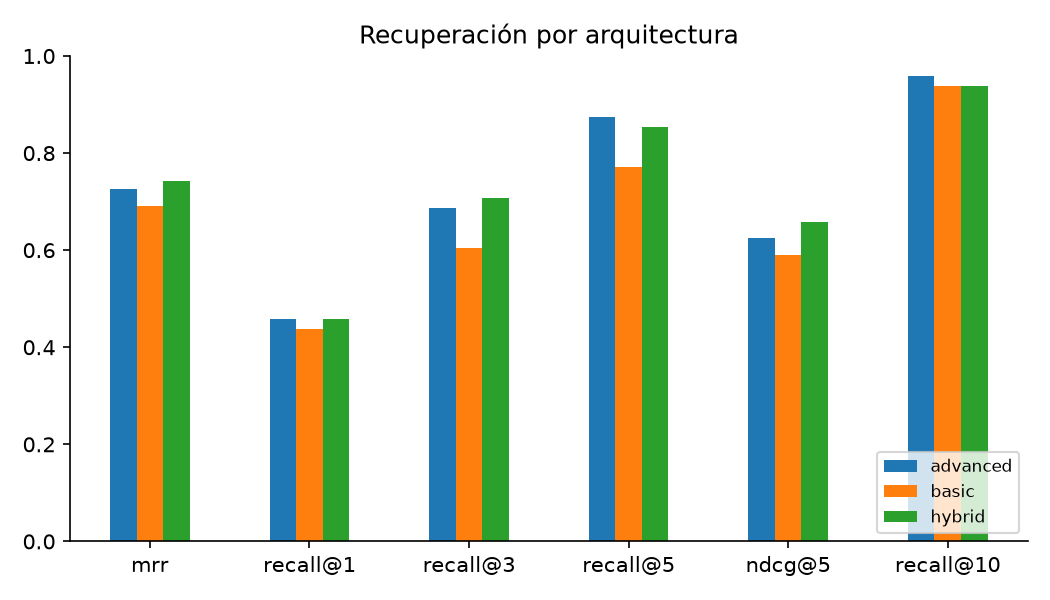

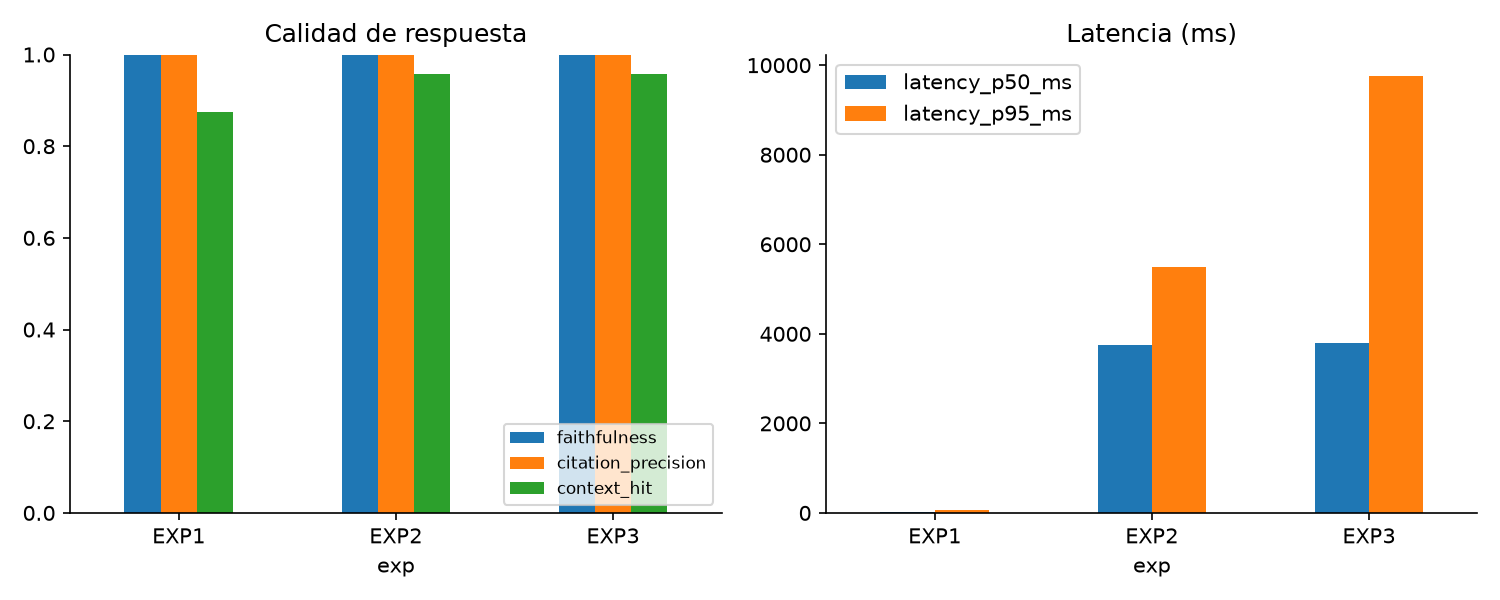

In [5]:
display(Image(str(paths['markdown'].parent / 'retrieval_metrics.png')))
display(Image(str(paths['markdown'].parent / 'e2e_metrics.png')))